In [1]:
import numpy as np
import torch
from typing import Optional, Tuple, List
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
class SegDataset(Dataset):
    """
    - Pairs images/masks by filename stem (e.g., a.jpg <-> a.png)
    - Image resize: BILINEAR; Mask resize: NEAREST (preserve labels)
    - Binary masks: any nonzero -> 1.0
    """
    def __init__(self, root: str, split: str = "train", img_size: int = 512):
        self.root = Path(root)
        img_dir = self.root / split / "images"
        msk_dir = self.root / split / "masks"

        imgs = sorted(p for p in img_dir.glob("*") if p.is_file())
        msks = {p.stem: p for p in msk_dir.glob("*") if p.is_file()}

        self.samples: List[Tuple[Path, Path]] = []
        for ip in imgs:
            mp = msks.get(ip.stem)
            if mp is not None:
                self.samples.append((ip, mp))

        if not self.samples:
            raise FileNotFoundError(f"No matched image/mask pairs under {img_dir} and {msk_dir}.")

        self.size = (img_size, img_size)

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, i: int) -> Tuple[torch.Tensor, torch.Tensor]:
        img_path, mask_path = self.samples[i]

        # --- Image: RGB, bilinear resize, [0,1] float32 to tensor [3,H,W]
        img = Image.open(img_path).convert("RGB").resize(self.size, Image.BILINEAR)
        img_np = (np.asarray(img, dtype=np.float32) / 255.0).transpose(2, 0, 1)  # 3,H,W
        img_t = torch.from_numpy(img_np)  # float32

        # --- Mask: if RGB use green channel; NEAREST resize; binarize >0
        mask_pil = Image.open(mask_path)
        if mask_pil.mode == "RGB":
            m = np.asarray(mask_pil, dtype=np.uint8)[:, :, 1]
        elif mask_pil.mode in ("L", "P"):
            m = np.asarray(mask_pil, dtype=np.uint8)
        else:
            m = np.asarray(mask_pil.convert("L"), dtype=np.uint8)

        m = Image.fromarray(m).resize(self.size, Image.NEAREST)
        m_np = (np.asarray(m, dtype=np.uint8) > 0).astype(np.float32)  # H,W -> {0.,1.}
        mask_t = torch.from_numpy(m_np).unsqueeze(0)  # 1,H,W

        return img_t, mask_t


# ---------------- Example usage ----------------
if __name__ == "__main__":
    dataset = SegDataset("/home/ehr/Desktop/anupama/plant/data", split="train", img_size=512)
    dl = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)

    imgs, masks = next(iter(dl))
    print("Images:", imgs.shape, imgs.dtype)  # [B,3,512,512], float32
    print("Masks :", masks.shape, masks.dtype, masks.min().item(), masks.max().item())  # [B,1,512,512], 0.0/1.0


Images: torch.Size([4, 3, 512, 512]) torch.float32
Masks : torch.Size([4, 1, 512, 512]) torch.float32 0.0 0.0


Images: torch.Size([4, 3, 512, 512]) torch.float32
Masks : torch.Size([4, 1, 512, 512]) torch.float32 0.0 0.0


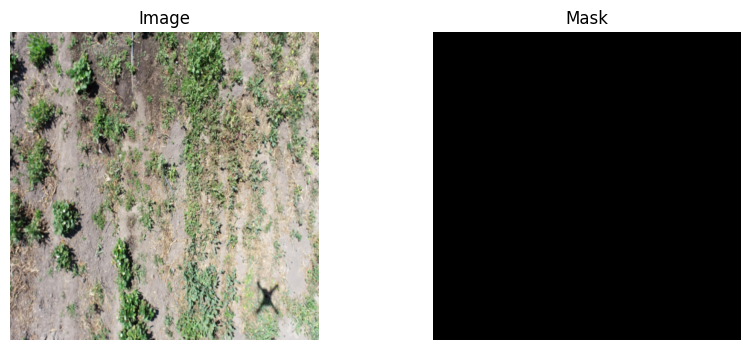

In [2]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from typing import Tuple, List

class SegDataset(Dataset):
    """
    - Pairs images/masks by filename stem (a.jpg <-> a.png)
    - Image resize: BILINEAR; Mask resize: NEAREST (preserve labels)
    - Binary masks: any nonzero -> 1.0
    """
    def __init__(self, root: str, split: str = "train", img_size: int = 512):
        self.root = Path(root)
        img_dir = self.root / split / "images"
        msk_dir = self.root / split / "masks"

        imgs = sorted(p for p in img_dir.glob("*") if p.is_file())
        msks = {p.stem: p for p in msk_dir.glob("*") if p.is_file()}

        self.samples: List[Tuple[Path, Path]] = []
        for ip in imgs:
            mp = msks.get(ip.stem)
            if mp is not None:
                self.samples.append((ip, mp))

        if not self.samples:
            raise FileNotFoundError(f"No matched image/mask pairs under {img_dir} and {msk_dir}.")

        self.size = (img_size, img_size)

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, i: int) -> Tuple[torch.Tensor, torch.Tensor]:
        img_path, mask_path = self.samples[i]

        # --- Image: RGB -> bilinear resize -> [0,1] float32 -> tensor [3,H,W]
        img = Image.open(img_path).convert("RGB").resize(self.size, Image.BILINEAR)
        img_np = (np.asarray(img, dtype=np.float32) / 255.0).transpose(2, 0, 1)  # 3,H,W
        img_t = torch.from_numpy(img_np)

        # --- Mask: if RGB use green channel; NEAREST resize; binarize >0
        mask_pil = Image.open(mask_path)
        if mask_pil.mode == "RGB":
            m = np.asarray(mask_pil, dtype=np.uint8)[:, :, 1]
        elif mask_pil.mode in ("L", "P"):
            m = np.asarray(mask_pil, dtype=np.uint8)
        else:
            m = np.asarray(mask_pil.convert("L"), dtype=np.uint8)

        m = Image.fromarray(m).resize(self.size, Image.NEAREST)
        m_np = (np.asarray(m, dtype=np.uint8) > 0).astype(np.float32)  # H,W in {0.,1.}
        mask_t = torch.from_numpy(m_np).unsqueeze(0)                   # 1,H,W

        return img_t, mask_t

# ---------------- Example usage + visualization ----------------
if __name__ == "__main__":
    dataset = SegDataset("/home/ehr/Desktop/anupama/plant/data", split="train", img_size=512)
    dl = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)

    imgs, masks = next(iter(dl))
    print("Images:", imgs.shape, imgs.dtype)  # [B,3,512,512]
    print("Masks :", masks.shape, masks.dtype, masks.min().item(), masks.max().item())  # [B,1,512,512], 0/1

    # visualize first sample without torchvision
    i = 0
    img_vis = (imgs[i].permute(1, 2, 0).numpy() * 255).astype(np.uint8)   # H,W,3 uint8
    mask_vis = masks[i, 0].numpy()                                        # H,W float {0,1}

    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1); plt.title("Image"); plt.axis("off"); plt.imshow(img_vis)
    plt.subplot(1,2,2); plt.title("Mask");  plt.axis("off"); plt.imshow(mask_vis, cmap="gray")
    plt.show()
